## ⚙️ **Libraries Import**

In [1]:
# Set seed for reproducibility
SEED = 100

import numpy as np

# Import necessary libraries
import os
from datetime import datetime

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
#from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## 🔧 **Automatic Configuration**

In [2]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        !ls "/kaggle/input/dataset"
        input_dir = Path('/kaggle/input/dataset/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locali
        input_dir = Path('../data/archive/')
        output_dir = Path('../data/output/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


🌍 Detetected enviroment: KAGGLE
masks_cleaned.npy  test_images.npy  train_data	      train_labels.csv
test_data	   test_masks.npy   train_images.npy  train_masks.npy
Input directory: /kaggle/input/dataset
Output directory: /kaggle/working


In [3]:
#creo cartella per i models
models_dir=OUTPUT_DIR/'models'
models_dir.mkdir(parents=True, exist_ok=True)

#setup Log file
csv_file = OUTPUT_DIR/"all_models_log.csv"

## **Constants**

In [4]:
#tutte le costanti utili in un unico posto :)

BATCH_SIZE = 64

#specify if you want fine tuning and img augmentation
FINE_TUNING = True
IMAGE_AUG = False

# ImageNet normalization statistics
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


## ⏳ **Data Loading**

In [5]:
# I numpy sono nel dataset ora (MESSI SUCCESSIVAMENTE) 
train_images = np.load(INPUT_DIR/'train_images.npy')
train_masks = np.load(INPUT_DIR/'masks_cleaned.npy')
test_images = np.load(INPUT_DIR/'test_images.npy')
test_masks = np.load(INPUT_DIR/'test_masks.npy')
train_labels = pd.read_csv(INPUT_DIR/'train_labels.csv')

train_images=train_images.astype('float32')
train_masks=train_masks.astype('float32')
test_images=test_images.astype('float32')
test_masks=test_masks.astype('float32')

print(type(train_images))

# Get class names
class_names = train_labels['label']
#print(class_names)

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train masks shape: {train_masks.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test masks shape: {test_masks.shape}")
print(f"Train labels shape: {train_labels.shape}")

<class 'numpy.ndarray'>
Data loaded sucessfully!
Train images shape: (629, 224, 224, 3)
Train masks shape: (629, 224, 224, 1)
Test images shape: (477, 224, 224, 3)
Test masks shape: (477, 224, 224, 1)
Train labels shape: (629, 2)


## 🔎 **Data Analysis**

In [6]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))

        sample_index      label
count            629        629
unique           629          4
top     img_0690.png  Luminal B
freq               1        219

--- Unique Labels ---
['Triple negative' 'Luminal B' 'Luminal A' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B          219       34.82
Luminal A          175       27.82
HER2(+)            159       25.28
Triple negative     76       12.08


In [7]:
#number of classes
NUM_CLASSES = len(unique_labels)

## 🔄 **Data Processing**

In [8]:
# Target preparation

# Define the mapping between textual labels and numerical value (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Add new column 'target' to train_labels dataframe
train_labels['target'] = train_labels['label'].map(label_mapping)
target=np.array(train_labels['target']).astype('int64')

counts = train_labels['target'].value_counts().sort_index().values
# weight = (num_total_training / (num_classes * num_for_class))
class_weights = (len(train_labels)/(NUM_CLASSES*counts))

# Create list useful later for tensor transformation
class_weights_list=list(class_weights)
print(f"Balanced WEIGHT for each class:\t{class_weights_list}")
class_weights_tensor=torch.tensor(class_weights_list, dtype=torch.float32).to(device)

Balanced WEIGHT for each class:	[0.8985714285714286, 0.7180365296803652, 0.9889937106918238, 2.0690789473684212]


In [9]:
# SPLIT in TRAIN & VAL

X_train , X_val, y_train, y_val = train_test_split(train_images, target, test_size=0.2, random_state=SEED,  stratify=target)

# Print the shapes of the resulting datasets
print("Training Data Shape:", X_train.shape)
print("Training Label Shape:", y_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Validation Label Shape:", y_val.shape)

Training Data Shape: (503, 224, 224, 3)
Training Label Shape: (503,)
Validation Data Shape: (126, 224, 224, 3)
Validation Label Shape: (126,)


In [10]:
# Define the input shape based on the training data
INPUT_SHAPE = (X_train.shape[3], X_train.shape[1], X_train.shape[2])
print(INPUT_SHAPE)

(3, 224, 224)


In [11]:
class MyDataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset with optional augmentation and normalization."""

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data).permute(0, 3, 1, 2)
        self.labels = torch.from_numpy(labels).squeeze().long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Clone to avoid modifying original
        label = self.labels[idx]

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [12]:
# Define geometric augmentations suitable for histology
train_transforms = transforms.Compose([
    #transforms.ToPILImage(), # Convert tensor/numpy to PIL to apply transforms
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=0, translate=(0.2, 0.2)),
    #transforms.RandomVerticalFlip(p=0.5),
    #transforms.RandomRotation(90),
    #transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05), # Simulate stain variations
    #transforms.ToTensor(), # Convert back to tensor
    # Normalization is handled inside MyDataset, so we don't add it here
])

# Convert numpy arrays to customized PyTorch datasets (pairs features with labels)
train_ds = MyDataset(X_train, y_train, augmentation=None, normalize_imagenet=True)
val_ds   = MyDataset(X_val, y_val, augmentation=None, normalize_imagenet=True)

In [13]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [14]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [15]:
# print batch shape
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([64, 3, 224, 224])
Labels batch shape: torch.Size([64])


## 🧮 **Network Parameters**

In [16]:
#MODEL PARAMETERS
EXPERIMENT_NAME = "fine_tuning_experiment"
# Choose your model : options -> "mobilenet_v3_small" "resnet18", "resnet50", "efficientnet_b0"
MODEL_NAME = "mobilenet_v3_small"

# Training parameters
LEARNING_RATE = 1e-3
EPOCHS = 300
PATIENCE = 50


# Regularisation
DROPOUT_RATE = 0.3      # Dropout probability
L1_LAMBDA = 0.0          # L1 penalty NON È USATA PER ORA
L2_LAMBDA = 0.0           # L2 penalty NON È USATA PER ORA

# Set up loss function
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

##  🧠 **Training Functions**

In [17]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, verbose=1, experiment_name=""):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': [],
        'best_epoch': 0
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(OUTPUT_DIR/'models'/(experiment_name+'_model.pt')))
        training_history['best_epoch'] = best_epoch
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))

    return model, training_history

## 🛠️ **Transfer Learning**

In [18]:
class TransferLearningModel(nn.Module):
    """
    CNN model with pretrained weights for transfer learning.

    IMPORTANT: This model expects ImageNet-normalized inputs!
    Images should be normalized with mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]
    """

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # 1 Load MobileNetV3Small backbone with ImageNet pretrained weights
        self.backbone = torchvision.models.mobilenet_v3_small(
            weights=torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
        )

        # 2. Freeze backbone if requested
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # 3. Replace the Fully Connected (fc) layer
        # Replace classifier (always trainable)
        in_features = self.backbone.classifier[0].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Linear(in_features, in_features),
            nn.Hardswish(),
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

In [19]:
# Create transfer learning model
tl_model = TransferLearningModel(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)

# Display model summary
summary(tl_model, input_size=INPUT_SHAPE)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
100%|██████████| 9.83M/9.83M [00:00<00:00, 54.7MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 112, 112]             432
       BatchNorm2d-2         [-1, 16, 112, 112]              32
         Hardswish-3         [-1, 16, 112, 112]               0
            Conv2d-4           [-1, 16, 56, 56]             144
       BatchNorm2d-5           [-1, 16, 56, 56]              32
              ReLU-6           [-1, 16, 56, 56]               0
 AdaptiveAvgPool2d-7             [-1, 16, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             136
              ReLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 16, 1, 1]             144
      Hardsigmoid-11             [-1, 16, 1, 1]               0
SqueezeExcitation-12           [-1, 16, 56, 56]               0
           Conv2d-13           [-1, 16, 56, 56]             256
      BatchNorm2d-14           [-1, 16,

In [20]:
# Setup training

#optimizer = torch.optim.AdamW(tl_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)
optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [21]:
%%time

# Train with transfer learning
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=1,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
)

final_val_f1 = round(max(tl_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')

Training 300 epochs...
Epoch   1/300 | Train: Loss=1.4342, F1=0.2291 | Val: Loss=1.4042, F1=0.1563
Epoch   2/300 | Train: Loss=1.3700, F1=0.2761 | Val: Loss=1.3857, F1=0.1392
Epoch   3/300 | Train: Loss=1.3069, F1=0.3253 | Val: Loss=1.3930, F1=0.2374
Epoch   4/300 | Train: Loss=1.2541, F1=0.3969 | Val: Loss=1.3794, F1=0.2903
Epoch   5/300 | Train: Loss=1.2248, F1=0.4253 | Val: Loss=1.4168, F1=0.2858
Epoch   6/300 | Train: Loss=1.2254, F1=0.4098 | Val: Loss=1.3953, F1=0.2736
Epoch   7/300 | Train: Loss=1.1778, F1=0.4823 | Val: Loss=1.4158, F1=0.2212
Epoch   8/300 | Train: Loss=1.1196, F1=0.4960 | Val: Loss=1.4427, F1=0.1983
Epoch   9/300 | Train: Loss=1.0996, F1=0.5249 | Val: Loss=1.5122, F1=0.2614
Epoch  10/300 | Train: Loss=1.0800, F1=0.5559 | Val: Loss=1.5034, F1=0.2556
Epoch  11/300 | Train: Loss=1.0099, F1=0.5848 | Val: Loss=1.5881, F1=0.1842
Epoch  12/300 | Train: Loss=1.0121, F1=0.5515 | Val: Loss=1.5750, F1=0.2301
Epoch  13/300 | Train: Loss=0.9751, F1=0.5785 | Val: Loss=1.6117,

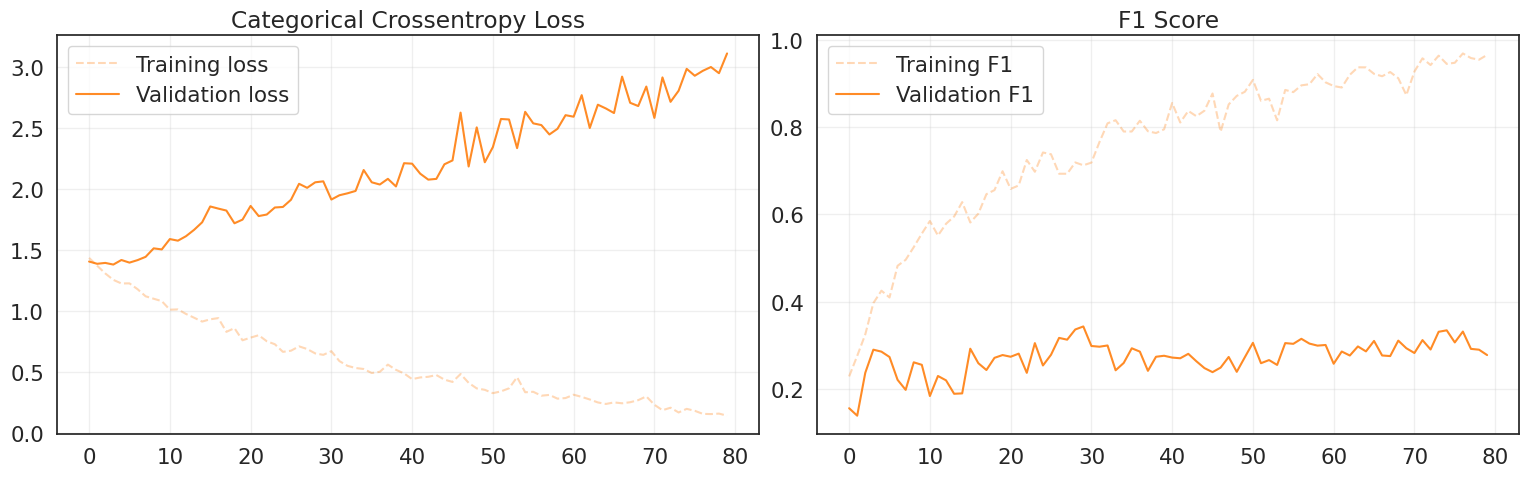

In [22]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.3810
Precision over the validation set: 0.3922
Recall over the validation set: 0.3810
F1 score over the validation set: 0.3748
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            28.57%
Luminal B            54.55%
HER2(+)              37.50%
Triple negative      13.33%
-----------------------------------


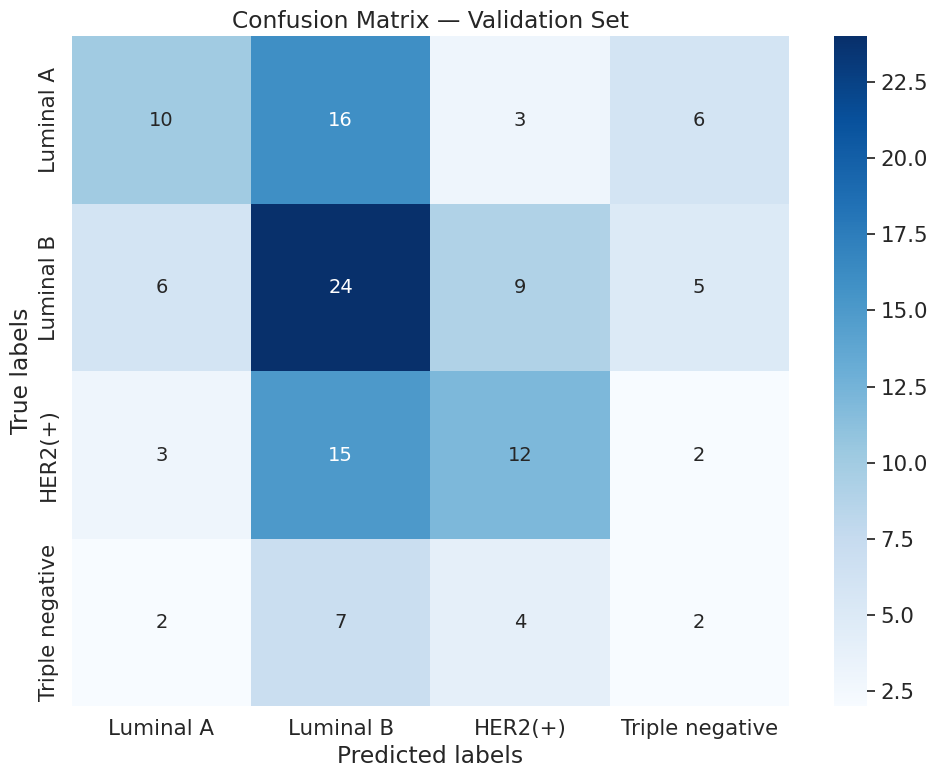

In [23]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = tl_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

### 📋 **MODELS LOG**

In [24]:
#UPDATING LOG
hyperparams = {
    "batch_size": BATCH_SIZE,
    "dropout_rate": DROPOUT_RATE,
    "l1_lambda": L1_LAMBDA,
    "l2_lambda": L2_LAMBDA,
    "patience": PATIENCE
}

row = {
    "time": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "experiment_name": EXPERIMENT_NAME,
    "model_name": MODEL_NAME,
    "fine_tuning": False,
    "img_augmentation": IMAGE_AUG,
    "val_loss": tl_history['val_loss'][tl_history['best_epoch']-1],
    "val_f1": tl_history['val_f1'][tl_history['best_epoch']-1],
    **hyperparams,
    "accuracy_LA": accuracy_LA,
    "accuracy_LB": accuracy_LB,
    "accuracy_H2": accuracy_H2,
    "accuracy_TN": accuracy_TN,
}

new_row = pd.DataFrame([row])
if os.path.exists(csv_file):
    models_log = pd.read_csv(csv_file)
    models_log = models_log[models_log['experiment_name'] != row['experiment_name']]  # rimuovi duplicato
    models_log = pd.concat([models_log, new_row], ignore_index=True)
    models_log = models_log.sort_values(by='val_f1', ascending=False, ignore_index=True)
else:
    models_log = new_row

models_log.to_csv(csv_file, index=False)

## 🛠️ **Fine-Tuning**

In [25]:
# Load the transfer learning model
ft_model = TransferLearningModel(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=False).to(device)
ft_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))

# Unfreeze the last N layers of the backbone
N_LAYERS_TO_UNFREEZE = 15

# First, freeze everything
for param in ft_model.backbone.parameters():
    param.requires_grad = False

# Unfreeze last N layers (excluding classifier which is always trainable)
backbone_layers = list(ft_model.backbone.features.children())
for layer in backbone_layers[-N_LAYERS_TO_UNFREEZE:]:
    for param in layer.parameters():
        param.requires_grad = True

# Count trainable parameters
total_params = sum(p.numel() for p in ft_model.parameters())
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Display which layers are trainable
print("\nTrainable layers:")
for name, param in ft_model.named_parameters():
    if param.requires_grad:
        print(f"  {name}: {param.numel():,} parameters")

Total parameters: 1,261,668
Trainable parameters: 927,008
Frozen parameters: 334,660

Trainable layers:
  backbone.features.0.0.weight: 432 parameters
  backbone.features.0.1.weight: 16 parameters
  backbone.features.0.1.bias: 16 parameters
  backbone.features.1.block.0.0.weight: 144 parameters
  backbone.features.1.block.0.1.weight: 16 parameters
  backbone.features.1.block.0.1.bias: 16 parameters
  backbone.features.1.block.1.fc1.weight: 128 parameters
  backbone.features.1.block.1.fc1.bias: 8 parameters
  backbone.features.1.block.1.fc2.weight: 128 parameters
  backbone.features.1.block.1.fc2.bias: 16 parameters
  backbone.features.1.block.2.0.weight: 256 parameters
  backbone.features.1.block.2.1.weight: 16 parameters
  backbone.features.1.block.2.1.bias: 16 parameters
  backbone.features.2.block.0.0.weight: 1,152 parameters
  backbone.features.2.block.0.1.weight: 72 parameters
  backbone.features.2.block.0.1.bias: 72 parameters
  backbone.features.2.block.1.0.weight: 648 parameter

In [26]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = MyDataset(X_train, y_train, augmentation=None, normalize_imagenet=True)
val_ft_ds = MyDataset(X_val, y_val, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [27]:
# Setup training with lower learning rate for fine-tuning
EXPERIMENT_NAME = "ft_"+EXPERIMENT_NAME
FT_LEARNING_RATE = 1e-4  # Lower learning rate for fine-tuning
optimizer = torch.optim.Adam(ft_model.parameters(), lr=FT_LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [28]:
%%time
# Fine-tune the model
ft_model, ft_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=5,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
)

final_val_f1 = max(ft_history['val_f1'])
print(f'Final validation f1: {final_val_f1:.4f}')

Training 300 epochs...
Epoch   1/300 | Train: Loss=0.5646, F1=0.8138 | Val: Loss=2.0361, F1=0.2979
Epoch   5/300 | Train: Loss=0.2978, F1=0.9301 | Val: Loss=1.9308, F1=0.3382
Epoch  10/300 | Train: Loss=0.1439, F1=0.9934 | Val: Loss=1.9615, F1=0.3479
Epoch  15/300 | Train: Loss=0.0680, F1=1.0000 | Val: Loss=1.9947, F1=0.3664
Epoch  20/300 | Train: Loss=0.0476, F1=1.0000 | Val: Loss=1.9983, F1=0.3719
Epoch  25/300 | Train: Loss=0.0316, F1=1.0000 | Val: Loss=1.9853, F1=0.4350
Epoch  30/300 | Train: Loss=0.0177, F1=1.0000 | Val: Loss=2.0577, F1=0.4073
Epoch  35/300 | Train: Loss=0.0138, F1=1.0000 | Val: Loss=2.1069, F1=0.3992
Epoch  40/300 | Train: Loss=0.0135, F1=1.0000 | Val: Loss=2.1580, F1=0.4323
Epoch  45/300 | Train: Loss=0.0078, F1=1.0000 | Val: Loss=2.2501, F1=0.4466
Epoch  50/300 | Train: Loss=0.0064, F1=1.0000 | Val: Loss=2.3090, F1=0.4466
Epoch  55/300 | Train: Loss=0.0076, F1=1.0000 | Val: Loss=2.3317, F1=0.4511
Epoch  60/300 | Train: Loss=0.0036, F1=1.0000 | Val: Loss=2.3946,

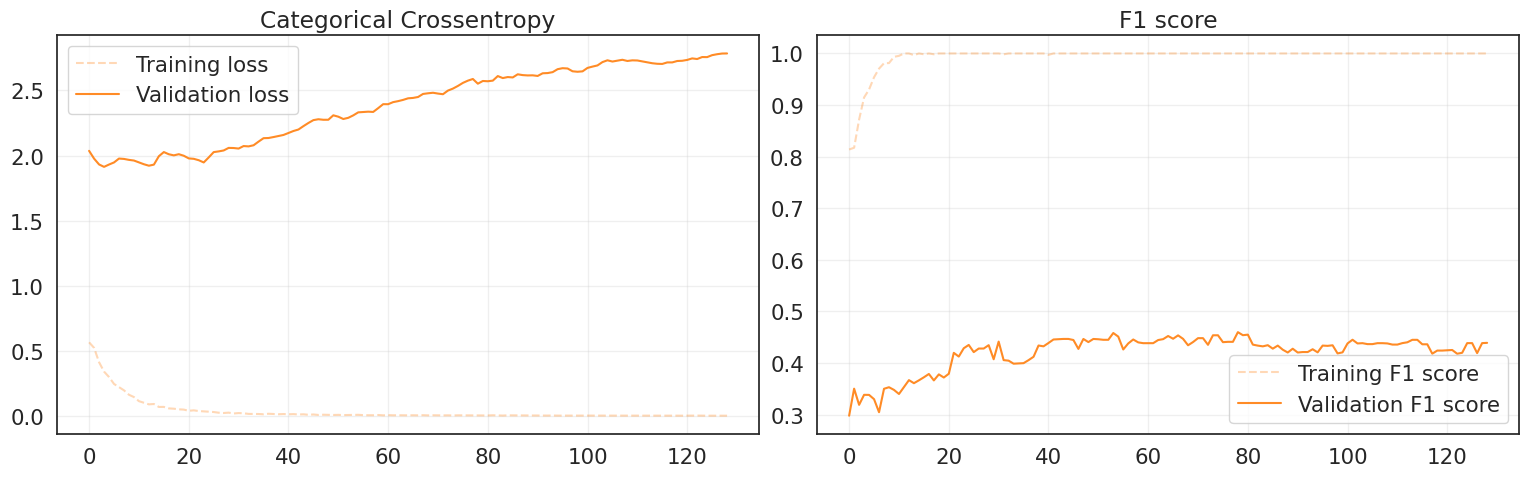

In [29]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(ft_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(ft_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(ft_history['train_f1'], label='Training F1 score', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(ft_history['val_f1'], label='Validation F1 score', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.4841
Precision over the validation set: 0.4868
Recall over the validation set: 0.4841
F1 score over the validation set: 0.4805
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            54.29%
Luminal B            50.00%
HER2(+)              50.00%
Triple negative      26.67%
-----------------------------------


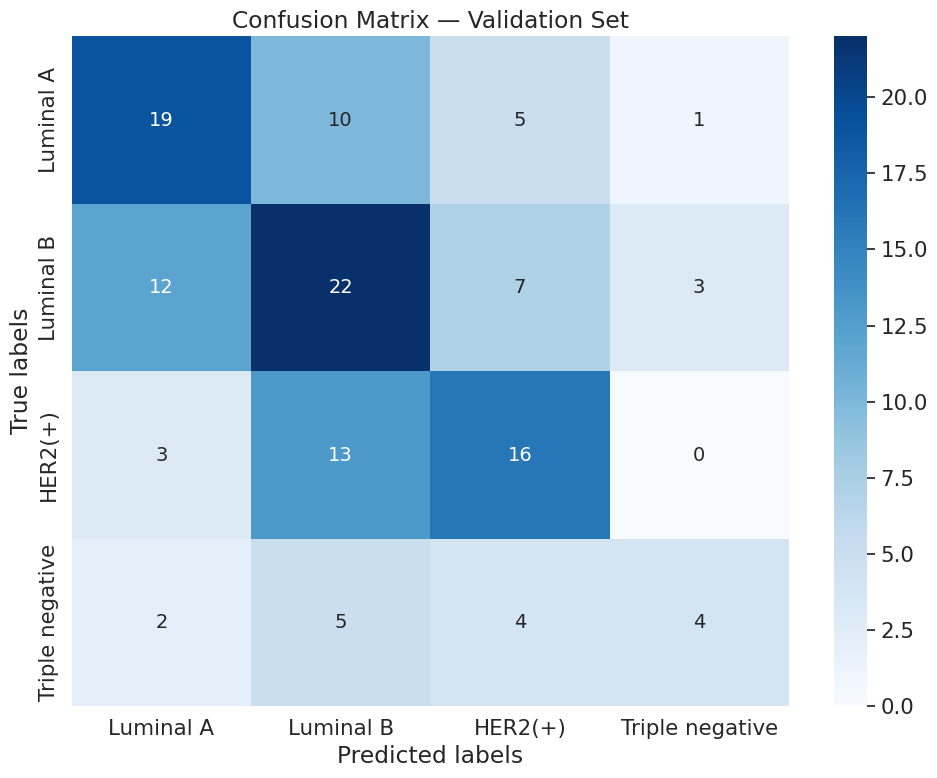

In [30]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_ft_preds, val_ft_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_ft_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = ft_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_ft_preds.append(preds)
        val_ft_targets.append(yb.numpy())

# Combine all batches into single arrays
val_ft_preds = np.concatenate(val_ft_preds)
val_ft_targets = np.concatenate(val_ft_targets)

# Calculate overall validation metrics
val_ft_acc = accuracy_score(val_ft_targets, val_ft_preds)
val_ft_prec = precision_score(val_ft_targets, val_ft_preds, average='weighted')
val_ft_rec = recall_score(val_ft_targets, val_ft_preds, average='weighted')
val_ft_f1 = f1_score(val_ft_targets, val_ft_preds, average='weighted')
print(f"Accuracy over the validation set: {val_ft_acc:.4f}")
print(f"Precision over the validation set: {val_ft_prec:.4f}")
print(f"Recall over the validation set: {val_ft_rec:.4f}")
print(f"F1 score over the validation set: {val_ft_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_ft_targets, val_ft_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

### 📋 **MODELS LOG**

In [31]:
#UPDATING LOG
hyperparams = {
    "batch_size": BATCH_SIZE,
    "dropout_rate": DROPOUT_RATE,
    "l1_lambda": L1_LAMBDA,
    "l2_lambda": L2_LAMBDA,
    "patience": PATIENCE
}

row = {
    "time": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "experiment_name": EXPERIMENT_NAME,
    "model_name": MODEL_NAME,
    "fine_tuning": True,
    "img_augmentation": IMAGE_AUG,
    "val_loss": ft_history['val_loss'][ft_history['best_epoch']-1],
    "val_f1": ft_history['val_f1'][ft_history['best_epoch']-1],
    **hyperparams,
    "accuracy_LA": accuracy_LA,
    "accuracy_LB": accuracy_LB,
    "accuracy_H2": accuracy_H2,
    "accuracy_TN": accuracy_TN,
}

new_row = pd.DataFrame([row])
if os.path.exists(csv_file):
    models_log = pd.read_csv(csv_file)
    models_log = models_log[models_log['experiment_name'] != row['experiment_name']]  # rimuovi duplicato
    models_log = pd.concat([models_log, new_row], ignore_index=True)
    models_log = models_log.sort_values(by='val_f1', ascending=False, ignore_index=True)
else:
    models_log = new_row

models_log.to_csv(csv_file, index=False)

## 🕹️ **Test Inference**

In [32]:
#PREPARE DATA FOR TESTING
test_ds = MyDataset(test_images, np.zeros(len(test_images)), augmentation=None, normalize_imagenet=True)
test_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [33]:
# Load the  model for inference
best_model = TransferLearningModel(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=False).to(device)
best_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))
best_model.eval()

print("Model "+EXPERIMENT_NAME+" loaded successfully!")

Model ft_fine_tuning_experiment loaded successfully!


In [34]:
# Collect predictions and ground truth labels
test_preds = []
with torch.no_grad():  # Disable gradient computation for inference
    for batch in test_loader:

        xb = batch[0].to(device)

        # Forward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_preds.append(preds)

# Combine all batches into single arrays
test_preds = np.concatenate(test_preds)

# Create CSV SUBMISSION
target_to_label = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}

# Ricostruisco il nome delle immagini: i=0 -> "img_0000.png", i=10 -> "img_0010.png"
filenames = [f"img_{i:04d}.png" for i in range(len(test_preds))]
predicted_labels = [target_to_label[p] for p in test_preds]

df_results = pd.DataFrame({
    "sample_index": filenames,
    "label": predicted_labels
})

csv_path = OUTPUT_DIR / 'test_predictions.csv'
df_results.to_csv(csv_path, index=False, header=True)
print(f"✅ test_predictions.csv created and saved successfully in: {csv_path}")

✅ test_predictions.csv created and saved successfully in: /kaggle/working/test_predictions.csv
